## II. Analysis on the dark kinases - PPI/GO for biological insights

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import re

import pandas as pd
import numpy as np
import re
from collections import Counter
from scipy.stats import fisher_exact

GO_COLS = [
    "Gene Ontology (biological process)",
    "Gene Ontology (cellular component)",
    "Gene Ontology (molecular function)",
    # "Gene Ontology (GO)",  # optional: the combined column, keep if you want
]

def _split_terms(x):
    """Split a semicolon-delimited GO string into cleaned terms."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return []
    if not isinstance(x, str):
        x = str(x)
    x = x.strip()
    if not x:
        return []
    # split on semicolons; also tolerate ' ; ' variants
    parts = [p.strip() for p in x.split(";")]
    # drop empties
    return [p for p in parts if p]

def _merge_terms(series):
    """Merge terms across rows -> unique, stable order."""
    seen = set()
    out = []
    for v in series.dropna():
        for term in _split_terms(v):
            if term not in seen:
                seen.add(term)
                out.append(term)
    return "; ".join(out) if out else np.nan

# (Optional) also keep a count of unique terms for each column
def _count_unique_terms(x):
    terms = []
    for v in x.dropna():
        terms.extend(_split_terms(v))
    return len(set(terms))

In [2]:
blib_screen_tp = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')

In [3]:
# blib_screen_tp = blib_screen_tp.loc[blib_screen_tp['substrate'].apply(lambda s:s[7]!='Y'),:]
substrates_background = pd.read_pickle('./substrates_background_12345.pkl')

In [4]:
dark_in_screen = ['PHKG1_HUMAN','KKCC1_HUMAN','ADCK1_HUMAN','DYRK4_HUMAN']

In [5]:
blib_screen_tp_mapped = pd.merge(substrates_background,blib_screen_tp,left_on = 'substrate_seq_15aa',right_on = 'substrate')

In [6]:
blib_screen_tp_mapped.drop_duplicates()

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
0,E9GFX1,34,Y,ASQLPHDYSSTPNGT,ASQLPHDYSSTPNGT,ABL2_HUMAN,True,sh2,sh2,1,1,0.235742,0.235742,0.02550,0.02550,False,True
1,E9GFX1,34,Y,ASQLPHDYSSTPNGT,ASQLPHDYSSTPNGT,FES_HUMAN,True,sh2,sh2,1,1,0.436085,0.436085,0.00000,0.00000,False,True
2,E9GFX1,34,Y,ASQLPHDYSSTPNGT,ASQLPHDYSSTPNGT,FRK_HUMAN,False,,sh2,1,0,-0.006437,NaN,0.47175,NaN,False,False
3,E9GFX1,34,Y,ASQLPHDYSSTPNGT,ASQLPHDYSSTPNGT,FYN_HUMAN,True,sh2,sh2,1,1,0.260150,0.260150,0.01175,0.01175,False,True
4,E9GFX1,34,Y,ASQLPHDYSSTPNGT,ASQLPHDYSSTPNGT,JAK2_HUMAN_1,False,,sh2,1,0,0.007332,NaN,0.48500,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336205,V9GYC4,198,T,DRKCKLQTRVHRKTL,DRKCKLQTRVHRKTL,M3K7_HUMAN,True,fha,fha;ww,2,1,0.371202,0.371202,0.00050,0.00050,False,True
336206,V9GYC4,198,T,DRKCKLQTRVHRKTL,DRKCKLQTRVHRKTL,PDPK1_HUMAN,False,,fha;ww,2,0,0.065528,NaN,0.30650,NaN,False,False
336207,V9GYC4,198,T,DRKCKLQTRVHRKTL,DRKCKLQTRVHRKTL,PHKG1_HUMAN,False,,fha;ww,2,0,-0.065831,NaN,0.04100,NaN,False,False
336208,V9GYC4,198,T,DRKCKLQTRVHRKTL,DRKCKLQTRVHRKTL,PLK1_HUMAN,False,,fha;ww,2,0,-0.400153,NaN,0.00000,NaN,False,False


In [7]:
use_promiscuity_thresh = True

In [8]:
if not use_promiscuity_thresh:
    blib_screen_tp_mapped_dark = blib_screen_tp_mapped.loc[blib_screen_tp_mapped['kinase'].isin(dark_in_screen)&(blib_screen_tp_mapped['true_positive']),:]
else:
    print('a')
    dat_all_blib_fp = blib_screen_tp.copy()
    total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
    pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
    fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
    fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
    fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']
    fp_stats = fp_stats.loc[(fp_stats['promiscuous_score']<0.3)&(fp_stats['tot_kinase']>5),:]
    blib_screen_tp_mapped_dark = blib_screen_tp_mapped.loc[blib_screen_tp_mapped['kinase'].isin(dark_in_screen)&(blib_screen_tp_mapped['true_positive']),:]
    blib_screen_tp_mapped_dark = blib_screen_tp_mapped_dark.loc[blib_screen_tp_mapped_dark['substrate_seq_15aa'].isin(fp_stats['substrate']),:]

a


In [9]:
fp_stats.shape

(1304, 4)

In [15]:
blib_screen_tp_mapped_dark.drop_duplicates(['kinase','substrate_x']).groupby('kinase').count()

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
kinase,,,,,,,,,,,,,,,,
ADCK1_HUMAN,56,56,56,56,56,56,56,56,56,56,56,56,56,56,56,56
KKCC1_HUMAN,479,479,479,479,479,479,479,479,479,479,479,479,479,479,479,479
PHKG1_HUMAN,224,224,224,224,224,224,224,224,224,224,224,224,224,224,224,224


In [55]:
blib_screen_tp_mapped_dark.loc[blib_screen_tp_mapped_dark['kinase']=='ADCK1_HUMAN',:].sort_values('binding_max').drop_duplicates('substrate_seq_15aa')

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
108203,Q9HAW4,1129,S,LADGDLHSDGPGRMR,LADGDLHSDGPGRMR,ADCK1_HUMAN,True,1433,1433;ww,2,1,0.213945,0.213945,0.03400,0.03400,False,True
356613,O43424,685,S,PYGTVLDSAVYEHVR,PYGTVLDSAVYEHVR,ADCK1_HUMAN,True,fha,1433;fha;ww,3,1,0.237508,0.237508,0.00925,0.03925,False,True
119829,P05107,745,S,FEKEKLKSQWNNDNP,FEKEKLKSQWNNDNP,ADCK1_HUMAN,True,fha,fha,1,1,0.243810,0.243810,0.03200,0.03200,False,True
109723,P51955,365,S,LKERKFLSLASNPEL,LKERKFLSLASNPEL,ADCK1_HUMAN,True,fha,fha,1,1,0.257289,0.257289,0.01225,0.01225,False,True
146252,Q53EL6,67,S,KRRLRKNSSRDSGRG,KRRLRKNSSRDSGRG,ADCK1_HUMAN,True,fha,fha;ww,2,1,0.269717,0.269717,0.02275,0.02275,False,True
36922,Q8IVW6,534,S,SLGSSASSSSSSHCS,SLGSSASSSSSSHCS,ADCK1_HUMAN,True,fha,1433;fha,2,1,0.274076,0.274076,0.02000,0.02000,False,True
325018,A0A6Q8KRG2,25,S,REYQQRNSPGVPTGA,REYQQRNSPGVPTGA,ADCK1_HUMAN,True,fha,fha,1,1,0.283919,0.283919,0.01600,0.01600,False,True
233151,Q9WTL8,97,S,RRRDKMNSFIDELAS,RRRDKMNSFIDELAS,ADCK1_HUMAN,True,fha,fha;ww,2,1,0.289433,0.289433,0.01700,0.01700,False,True
239143,P22449,142,S,DRISTRRSSYEDSSL,DRISTRRSSYEDSSL,ADCK1_HUMAN,True,1433;fha,1433;fha;ww,3,2,0.293602,0.293602,0.00550,0.00550,False,True
133077,Q15788,979,T,RFPPQQATPPLIMEE,RFPPQQATPPLIMEE,ADCK1_HUMAN,True,fha,1433;fha;ww,3,1,0.297041,0.297041,0.01525,0.01525,False,True


In [17]:
# Paths
SUB_ANN_PATH = "./dark_kinase_in/substrate_dark_idmapping.tsv"
BG_PATH = "./dark_kinase_in/st_background_uniprot_mapping.tsv"

# Load
df_hits = blib_screen_tp_mapped_dark.copy()
sub_ann = pd.read_csv(SUB_ANN_PATH, sep="\t")
bg_ann = pd.read_csv(BG_PATH, sep="\t")

In [18]:
collapse_to_substrate_seq_15aa = True

In [19]:
if collapse_to_substrate_seq_15aa:
    df = pd.merge(blib_screen_tp_mapped,bg_ann,left_on = 'substrate_x',right_on = 'From')
    
    df = df.loc[(df['Organism']=='Homo sapiens (Human)')|
        (df['Organism']=='Mus musculus (Mouse)'),:]
    
    # df = df.loc[(df['Organism']=='Homo sapiens (Human)'),:]
    
    go_counts = (
        df.groupby("substrate_y", as_index=False)[GO_COLS]
          .agg(_count_unique_terms)
          .rename(columns={c: f"{c}__n_terms" for c in GO_COLS})
    )
    go_merged = (
        df.groupby("substrate_y", as_index=False)[GO_COLS]
          .agg(_merge_terms)
    )
    
    go_merged = go_merged.merge(go_counts, on="substrate_y", how="left")
    
    # If you want to merge back onto the original df:
    df_with_merged_go = df.drop(columns=GO_COLS, errors="ignore").merge(
        go_merged, on="substrate_y", how="left"
    )
    bg_ann_final = df_with_merged_go.drop_duplicates().copy()


    df = pd.merge(blib_screen_tp_mapped_dark,bg_ann,left_on = 'substrate_x',right_on = 'From')

    df = df.loc[(df['Organism']=='Homo sapiens (Human)')|
        (df['Organism']=='Mus musculus (Mouse)'),:]
    
    # df = df.loc[(df['Organism']=='Homo sapiens (Human)'),:]
    
    go_merged = (
        df.groupby("substrate_y", as_index=False)[GO_COLS]
          .agg(_merge_terms)
    )
    
    go_counts = (
        df.groupby("substrate_y", as_index=False)[GO_COLS]
          .agg(_count_unique_terms)
          .rename(columns={c: f"{c}__n_terms" for c in GO_COLS})
    )
    
    go_merged = go_merged.merge(go_counts, on="substrate_y", how="left")
    
    # If you want to merge back onto the original df:
    df_with_merged_go = df.drop(columns=GO_COLS, errors="ignore").merge(
        go_merged, on="substrate_y", how="left"
    )
    sub_ann_final = df_with_merged_go.drop_duplicates().copy()

    bg_ann_final = bg_ann_final.groupby(['substrate_seq_15aa','kinase']).head(1)
    
    sub_ann_final = sub_ann_final.groupby(['substrate_seq_15aa','kinase']).head(1)
else:
    bg_ann_final = pd.merge(blib_screen_tp_mapped,bg_ann,left_on = 'substrate_x',right_on = 'From').drop_duplicates()
    sub_ann_final = df = pd.merge(blib_screen_tp_mapped_dark,bg_ann,left_on = 'substrate_x',right_on = 'From').drop_duplicates()

In [20]:
sub_ann_final.loc[(sub_ann_final['substrate_seq_15aa']== 'RGRKRFVSEGDGGRL')&
    (sub_ann_final['kinase']=='PHKG1_HUMAN'),:]

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,...,Sequence,Function [CC],EC number,Gene Ontology (GO),Gene Ontology (biological process),Gene Ontology (cellular component),Gene Ontology (molecular function),Gene Ontology (biological process)__n_terms,Gene Ontology (cellular component)__n_terms,Gene Ontology (molecular function)__n_terms
171,Q53EL6,457,S,RGRKRFVSEGDGGRL,RGRKRFVSEGDGGRL,PHKG1_HUMAN,True,1433,1433;fha;ww,3,...,MDVENEQILNVNPADPDNLSDSLFSGDEENAGTEEIKNEINGNWIS...,FUNCTION: Inhibits translation initiation and ...,NaN,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,apoptotic process [GO:0006915]; BMP signaling ...,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,RNA binding [GO:0003723],14,3,1


In [40]:
import pandas as pd

def filter_by_go_term(df, go_term):
    """
    Filter dataframe rows where a GO term appears in ANY GO annotation column.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Your dataframe with Gene Ontology columns
    go_term : str
        The term to search for. Accepts:
          - GO ID:      "GO:0005739"
          - Term name:  "mitochondrion"
          - Partial:    "mitochondri"  (matches all mitochondrial terms)
    
    Returns:
    --------
    pd.DataFrame : Filtered rows
    """
    go_cols = [col for col in df.columns if 'Gene Ontology' in col or col == 'GO']
    
    if not go_cols:
        raise ValueError("No Gene Ontology columns found")
    
    mask = pd.Series(False, index=df.index)
    for col in go_cols:
        mask |= df[col].astype(str).str.contains(
            go_term,
            case=False,   # case-insensitive
            na=False,     # NaN → False (no error)
            regex=False   # treat as literal (safe for "GO:..." colons)
        )
    
    result = df[mask].copy()
    print(f"Found {len(result)} rows matching '{go_term}' across {len(go_cols)} GO columns")
    return result


# ── If you want to search a SPECIFIC GO column only ────────────────────────
def filter_by_go_term_in_column(df, go_term, column="Gene Ontology (biological process)"):
    mask = df[column].astype(str).str.contains(go_term, case=False, na=False, regex=False)
    return df[mask].copy()




In [56]:
# ── Usage ──────────────────────────────────────────────────────────────────
# Search all GO columns (recommended):
df_adck1_curr = sub_ann_final.loc[(sub_ann_final['kinase']=='ADCK1_HUMAN')]
hits = filter_by_go_term(df_adck1_curr, "GO:0005739")          # mitochondrion by ID
# hits = filter_by_go_term(df, "mitochondrion")        # by name
# hits = filter_by_go_term(df, "mitochondri")          # partial — catches all mitochondrial terms
# hits = filter_by_go_term(df, "apoptotic process")    # biological process term
# hits = filter_by_go_term(df, "ATP binding")          # molecular function

# Search one column only:
# hits = filter_by_go_term_in_column(df, "kinase activity", "Gene Ontology (molecular function)")
# hits = filter_by_go_term_in_column(df, "cell division", "Gene Ontology (biological process)")

Found 4 rows matching 'GO:0005739' across 7 GO columns


In [57]:
hits

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,...,Sequence,Function [CC],EC number,Gene Ontology (GO),Gene Ontology (biological process),Gene Ontology (cellular component),Gene Ontology (molecular function),Gene Ontology (biological process)__n_terms,Gene Ontology (cellular component)__n_terms,Gene Ontology (molecular function)__n_terms
108,Q01860,288,S,RRQKGKRSSSDYAQR,RRQKGKRSSSDYAQR,ADCK1_HUMAN,True,fha,fha;ww,2,...,MAGHLASDFAFSPPPGGGGDGPGGPEPGWVDPRTWLSFQGPPGGPG...,FUNCTION: Transcription factor that binds to t...,NaN,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,anatomical structure morphogenesis [GO:0009653...,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,DNA binding [GO:0003677]; DNA-binding transcri...,18,7,12
152,Q14790,305,S,IYQLMDHSNMDCFIC,IYQLMDHSNMDCFIC,ADCK1_HUMAN,True,1433;ww,1433;ww,2,...,MDFSRNLYDIGEQLDSEDLASLKFLSLDYIPQRKQEPIKDALMLFQ...,FUNCTION: Thiol protease that plays a key role...,3.4.22.61,CD95 death-inducing signaling complex [GO:0031...,angiogenesis [GO:0001525]; apoptotic process [...,CD95 death-inducing signaling complex [GO:0031...,cysteine-type endopeptidase activity [GO:00041...,45,13,10
174,Q5S007,826,T,GPLFPDKTSNLRKQT,GPLFPDKTSNLRKQT,ADCK1_HUMAN,True,fha,fha,1,...,MASGSCQGCEEDEETLKKLIVRLNNVQEGKQIETLVQILEDLLVFT...,FUNCTION: Serine/threonine-protein kinase whic...,2.7.11.1; 3.6.5.-,amphisome [GO:0044753]; autolysosome [GO:00447...,autophagy [GO:0006914]; calcium-mediated signa...,amphisome [GO:0044753]; autolysosome [GO:00447...,actin binding [GO:0003779]; ATP binding [GO:00...,90,45,27
211,Q9BSQ5,384,S,GRGIITDSFGRHRRA,GRGIITDSFGRHRRA,ADCK1_HUMAN,True,fha,fha;ww,2,...,MEEEGKKGKKPGIVSPFKRVFLKGEKSRDKKAHEKVTERRPLHTVV...,FUNCTION: Component of the CCM signaling pathw...,NaN,cytoplasm [GO:0005737]; mitochondrion [GO:0005...,blood vessel endothelial cell differentiation ...,cytoplasm [GO:0005737]; mitochondrion [GO:0005...,NaN,17,3,0


In [51]:
df_adck1_curr.sort_values

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,...,Sequence,Function [CC],EC number,Gene Ontology (GO),Gene Ontology (biological process),Gene Ontology (cellular component),Gene Ontology (molecular function),Gene Ontology (biological process)__n_terms,Gene Ontology (cellular component)__n_terms,Gene Ontology (molecular function)__n_terms
19,O60331,553,T,QPRYRRRTQSSGQDG,QPRYRRRTQSSGQDG,ADCK1_HUMAN,True,fha,fha,1,...,MELEVPDEAESAEAGAVPSEAAWAAESGAAAGLAQKKAAPTEVLSM...,FUNCTION: Catalyzes the phosphorylation of pho...,2.7.1.68,adherens junction [GO:0005912]; cytosol [GO:00...,actin cytoskeleton organization [GO:0030036]; ...,adherens junction [GO:0005912]; cytosol [GO:00...,1-phosphatidylinositol-4-phosphate 5-kinase ac...,19,12,4
35,P05107,745,S,FEKEKLKSQWNNDNP,FEKEKLKSQWNNDNP,ADCK1_HUMAN,True,fha,fha,1,...,MLGLRPPLLALVGLLSLGCVLSQECTKFKVSSCRECIESGPGCTWC...,FUNCTION: Integrin ITGAL/ITGB2 is a receptor f...,NaN,cell surface [GO:0009986]; external side of pl...,amyloid-beta clearance [GO:0097242]; apoptotic...,cell surface [GO:0009986]; external side of pl...,amyloid-beta binding [GO:0001540]; cell adhesi...,33,16,8
45,P10721,959,S,DHSVRINSVGSTASS,DHSVRINSVGSTASS,ADCK1_HUMAN,True,fha,1433;fha,2,...,MRGARGAWDFLCVLLLLLRVQTGSSQPSVSPGEPSPPSIHPGKSDL...,FUNCTION: Tyrosine-protein kinase that acts as...,2.7.10.1,acrosomal vesicle [GO:0001669]; cell-cell junc...,actin cytoskeleton organization [GO:0030036]; ...,acrosomal vesicle [GO:0001669]; cell-cell junc...,ATP binding [GO:0005524]; cytokine binding [GO...,70,8,10
86,P41235,142,S,DRISTRRSSYEDSSL,DRISTRRSSYEDSSL,ADCK1_HUMAN,True,1433;fha,1433;fha;ww,3,...,MRLSKTLVDMDMADYSAALDPAYTTLEFENVQVLTMGNDTSPSEGT...,FUNCTION: Transcriptional regulator which cont...,NaN,chromatin [GO:0000785]; cytoplasm [GO:0005737]...,blood coagulation [GO:0007596]; cell different...,chromatin [GO:0000785]; cytoplasm [GO:0005737]...,chromatin binding [GO:0003682]; DNA binding [G...,28,5,15
98,P51955,365,S,LKERKFLSLASNPEL,LKERKFLSLASNPEL,ADCK1_HUMAN,True,fha,fha,1,...,MPSRAEDYEVLYTIGTGSYGRCQKIRRKSDGKILVWKELDYGSMTE...,FUNCTION: Protein kinase which is involved in ...,2.7.11.1,centrosome [GO:0005813]; ciliary basal body [G...,blastocyst development [GO:0001824]; cell divi...,centrosome [GO:0005813]; ciliary basal body [G...,ATP binding [GO:0005524]; metal ion binding [G...,15,16,6
104,P60484,229,S,VKIYSSNSGPTRRED,VKIYSSNSGPTRRED,ADCK1_HUMAN,True,1433;fha;ww,1433;fha;ww,3,...,MTAIIKEIVSRNKRRYQEDGFDLDLTYIYPNIIAMGFPAERLEGVY...,FUNCTION: Dual-specificity protein phosphatase...,3.1.3.-; 3.1.3.16; 3.1.3.48; 3.1.3.67,apical plasma membrane [GO:0016324]; cell proj...,adult behavior [GO:0030534]; apoptotic process...,apical plasma membrane [GO:0016324]; cell proj...,anaphase-promoting complex binding [GO:0010997...,58,15,18
108,Q01860,288,S,RRQKGKRSSSDYAQR,RRQKGKRSSSDYAQR,ADCK1_HUMAN,True,fha,fha;ww,2,...,MAGHLASDFAFSPPPGGGGDGPGGPEPGWVDPRTWLSFQGPPGGPG...,FUNCTION: Transcription factor that binds to t...,NaN,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,anatomical structure morphogenesis [GO:0009653...,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,DNA binding [GO:0003677]; DNA-binding transcri...,18,7,12
117,Q08379,37,S,REYQQRNSPGVPTGA,REYQQRNSPGVPTGA,ADCK1_HUMAN,True,fha,fha,1,...,MWPQPRLPPRPAMSEETRQSKLAAAKKKLREYQQRNSPGVPTGAKK...,FUNCTION: Peripheral membrane component of the...,NaN,cis-Golgi network [GO:0005801]; COPII-coated E...,asymmetric cell division [GO:0008356]; centros...,cis-Golgi network [GO:0005801]; COPII-coated E...,cadherin binding [GO:0045296]; identical prote...,16,10,6
149,Q14721,805,S,ESSPLPTSPKFLRQN,ESSPLPTSPKFLRQN,ADCK1_HUMAN,True,fha,fha,1,...,MPAGMTKHGSRSTSSLPPEPMEIVRSKACSRRVRLNVGGLAHEVLW...,FUNCTION: Voltage-gated potassium channel that...,NaN,apical plasma membrane [GO:0016324]; axon [GO:...,action potential [GO:0001508]; cellular respon...,apical plasma membrane [GO:0016324]; axon [GO:...,delayed rectifier potassium channel activity [...,22,16,6

In [27]:
sub_ann = sub_ann_final.copy()

In [28]:
bg_ann = bg_ann_final.copy()

In [29]:
reduce_to_seq = False

In [30]:
GO_RE = re.compile(r"(GO:\d{7})")

def extract_go_ids(x):
    if not isinstance(x, str):
        return []
    return GO_RE.findall(x)

def build_go_map(df,reduce_to_seq = False):
    go_map = {}
    # print(df.columns)
    if reduce_to_seq:
        for _, r in df.iterrows():
            gos = set()
            for col in GO_COLS:
                gos |= set(extract_go_ids(r.get(col, "")))
            go_map[r["substrate_seq_15aa"]] = gos
    else:
        for _, r in df.iterrows():
            
            gos = set()
            for col in GO_COLS:
                gos |= set(extract_go_ids(r.get(col, "")))
            go_map[r["substrate_x"]] = gos
    return go_map

hit_go = build_go_map(sub_ann,reduce_to_seq)
bg_go = build_go_map(bg_ann,reduce_to_seq)

In [31]:
print('number of substrate seq in bg:')
print(blib_screen_tp_mapped['substrate_seq_15aa'].drop_duplicates().shape[0])
print('number of substrate acc in bg:')
print(bg_ann['substrate_x'].drop_duplicates().shape[0])
print('number of substrate seq in hits:')
print(blib_screen_tp_mapped_dark['substrate_seq_15aa'].drop_duplicates().shape[0])
print('number of substrate acc in hits:')
print(sub_ann['substrate_x'].drop_duplicates().shape[0])

number of substrate seq in bg:
3886
number of substrate acc in bg:
1271
number of substrate seq in hits:
273
number of substrate acc in hits:
228


In [32]:
# 1249*1

In [33]:
def go_enrichment(hit_go, bg_go, min_bg=0,max_bg = 300):

    bg_subs_only = set(bg_go.keys()) - set(hit_go.keys())
    bg_go_clean = {s: bg_go[s] for s in bg_subs_only}

    hit_subs = set(hit_go.keys())
    bg_subs = set(bg_go_clean.keys())
    
    total_hit = len(hit_subs)
    total_bg = len(bg_subs)


    bg_counts = Counter(
        go for s in bg_subs for go in bg_go.get(s, [])
    )

    rows = []

    for go_id, bg_n in bg_counts.items():
        if (bg_n < min_bg) or (bg_n > max_bg):
            continue

        hit_n = sum(go_id in hit_go.get(s, set()) for s in hit_subs)
        if hit_n == 0:
            continue

        odds, p = fisher_exact(
            [[hit_n, total_hit - hit_n],
             [bg_n, total_bg - bg_n]],
            alternative="greater"
        )

        rows.append({
            "GO_ID": go_id,
            "hit_with_GO": hit_n,
            "total_hits": total_hit,
            "bg_with_GO": bg_n,
            "total_bg": total_bg,
            "odds_ratio": odds,
            "p_value": p
        })

    return pd.DataFrame(rows).sort_values("p_value")

GO_NAME_RE = re.compile(r"(.+?)\s*\[(GO:\d{7})\]")

def extract_go_id_name_pairs(val):
    """
    Returns list of (GO_ID, GO_NAME)
    """
    if not isinstance(val, str):
        return []
    pairs = []
    for part in re.split(r";", val):
        m = GO_NAME_RE.search(part)
        if m:
            name = m.group(1).strip()
            go_id = m.group(2)
            pairs.append((go_id, name))
    return pairs

def build_go_name_map(df):
    go_map = {}
    for _, r in df.iterrows():
        for col in GO_COLS:
            for go_id, go_name in extract_go_id_name_pairs(r.get(col, "")):
                # keep first seen name (they are consistent across UniProt)
                if go_id not in go_map:
                    go_map[go_id] = go_name
    return go_map


def build_go_type_map(df):
    go_map = {}
    for _, r in df.iterrows():
        for col in GO_COLS:
            for go_id, go_name in extract_go_id_name_pairs(r.get(col, "")):
                # keep first seen name (they are consistent across UniProt)
                if go_id not in go_map:
                    go_map[go_id] = col
    return go_map

go_name_map = {}
go_name_map.update(build_go_name_map(sub_ann))
go_name_map.update(build_go_name_map(bg_ann))

go_type_map = {}
go_type_map.update(build_go_type_map(sub_ann))
go_type_map.update(build_go_type_map(bg_ann))

def bh_fdr(pvals):
    p = np.asarray(pvals)
    n = len(p)
    idx = np.argsort(p)
    q = np.empty(n)
    prev = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        q_val = p[idx[i]] * n / rank
        prev = min(prev, q_val)
        q[idx[i]] = prev
    return q
go_by_kinase = {}



for k in df_hits["kinase"].unique():
    print(k)
    if reduce_to_seq:
        subs_k = set(df_hits.loc[df_hits["kinase"] == k, "substrate_seq_15aa"])
    else:
        subs_k = set(df_hits.loc[df_hits["kinase"] == k, "substrate_x"])
    hit_go_k = {s: hit_go[s] for s in subs_k if s in hit_go}
    
    df_go_enrich = go_enrichment(hit_go_k, bg_go, min_bg=0, max_bg = 300)
    # df_go_enrich = go_enrichment(hit_go_k, bg_go, min_bg=20, max_bg = 150)
    df_go_enrich["q_value"] = bh_fdr(df_go_enrich["p_value"].values)
    df_go_enrich["GO_name"] = df_go_enrich["GO_ID"].map(go_name_map)
    df_go_enrich["GO_type"] = df_go_enrich["GO_ID"].map(go_type_map)
    df_go_enrich = df_go_enrich[
    ["GO_ID", "GO_name","GO_type",
     "hit_with_GO", "total_hits",
     "bg_with_GO", "total_bg",
     "odds_ratio", "p_value", "q_value"]
]
    go_by_kinase[k] = df_go_enrich


KKCC1_HUMAN
PHKG1_HUMAN
ADCK1_HUMAN


In [35]:
k

'ADCK1_HUMAN'

In [34]:
df_hits.loc[df_hits["kinase"] == k, :]

,substrate_x,p_ind,p_aa,substrate_seq_15aa,substrate_y,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit,fp_sub,true_positive
4231,A0A0G2K1S9,393,S,GRGIITDSFGRHRRA,GRGIITDSFGRHRRA,ADCK1_HUMAN,True,fha,fha;ww,2,1,0.342385,0.342385,0.00325,0.00325,False,True
8791,P22449,142,S,DRISTRRSSYEDSSL,DRISTRRSSYEDSSL,ADCK1_HUMAN,True,1433;fha,1433;fha;ww,3,2,0.293602,0.293602,0.00550,0.00550,False,True
11439,Q5I6B8,552,T,QPRYRRRTQSSGQDG,QPRYRRRTQSSGQDG,ADCK1_HUMAN,True,fha,fha,1,1,1.102038,1.102038,0.00000,0.00000,False,True
13073,Q9JID1,67,S,KRRLRKNSSRDSGRG,KRRLRKNSSRDSGRG,ADCK1_HUMAN,True,fha,fha;ww,2,1,0.269717,0.269717,0.02275,0.02275,False,True
17329,O60331,553,T,QPRYRRRTQSSGQDG,QPRYRRRTQSSGQDG,ADCK1_HUMAN,True,fha,fha,1,1,1.102038,1.102038,0.00000,0.00000,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
371554,Q15788,979,T,RFPPQQATPPLIMEE,RFPPQQATPPLIMEE,ADCK1_HUMAN,True,fha,1433;fha;ww,3,1,0.297041,0.297041,0.01525,0.01525,False,True
371624,Q5S007,826,T,GPLFPDKTSNLRKQT,GPLFPDKTSNLRKQT,ADCK1_HUMAN,True,fha,fha,1,1,0.314685,0.314685,0.00900,0.00900,False,True
373376,A0A7P0T8S1,741,T,GPLFPDKTSNLRKQT,GPLFPDKTSNLRKQT,ADCK1_HUMAN,True,fha,fha,1,1,0.314685,0.314685,0.00900,0.00900,False,True
375458,B5MCN7,828,T,RFPPQQATPPLIMEE,RFPPQQATPPLIMEE,ADCK1_HUMAN,True,fha,1433;fha;ww,3,1,0.297041,0.297041,0.01525,0.01525,False,True


In [36]:
tmp_dat = go_by_kinase['ADCK1_HUMAN']
tmp_dat_ADCK1_HUMAN = tmp_dat.loc[(tmp_dat['bg_with_GO']>11)&(tmp_dat['bg_with_GO']<150)&(tmp_dat['hit_with_GO']>3)
    &(tmp_dat['p_value']<0.2),:].groupby('GO_type').head(7).sort_values(['GO_type','p_value'],ascending = True)
tmp_dat_ADCK1_HUMAN['kinase'] = 'ADCK1'

In [299]:
tmp_dat = go_by_kinase['PHKG1_HUMAN']
tmp_dat_PHKG1_HUMAN = tmp_dat.loc[(tmp_dat['bg_with_GO']>11)&(tmp_dat['bg_with_GO']<150)&(tmp_dat['hit_with_GO']>2)
    &(tmp_dat['p_value']<0.2),:].groupby('GO_type').head(7).sort_values(['GO_type','p_value'],ascending = True)
tmp_dat_PHKG1_HUMAN['kinase'] = 'PHKG1'
# tmp_dat.loc[(tmp_dat['bg_with_GO']>11)&(tmp_dat['bg_with_GO']<150)&(tmp_dat['hit_with_GO']>2),:].groupby('GO_type').head(3).sort_values(['GO_type','hit_with_GO'],ascending = False)

In [300]:
tmp_dat = go_by_kinase['KKCC1_HUMAN']
tmp_dat_KKCC1_HUMAN = tmp_dat.loc[(tmp_dat['bg_with_GO']>11)&(tmp_dat['bg_with_GO']<150)&(tmp_dat['hit_with_GO']>2)
    &(tmp_dat['p_value']<0.2),:].groupby('GO_type').head(7).sort_values(['GO_type','p_value'],ascending = True)
tmp_dat_KKCC1_HUMAN['kinase'] = 'KKCC1'

In [301]:
import numpy as np
import pandas as pd
import textwrap

def wrap_text(s, width=30):
    return "\n".join(textwrap.wrap(str(s), width=width))
from plotnine import *

def plot_go_enrichment_faceted_plotnine(df, top_n=5, figsize=(12, 11), output_file=None, dpi=300,kinase_name = ''):
    """
    Faceted GO enrichment plot (plotnine) with dot size ~ gene_ratio and x = -log10(p_value).

    Expected columns:
      - GO_name
      - GO_type
      - hit_with_GO
      - total_hits
      - p_value
    """
    # ---- process data ----
    df = df.copy()

    # Category label to match your previous mapping keys
    df["GO_category"] = (
        df["GO_type"]
        .astype(str)
        .str.replace("Gene Ontology ", "", regex=False)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
        .str.lower()
    )

    

    # Short labels (50 chars + ...)
    # df["GO_name_short"] = df["GO_name"].astype(str).str.slice(0, 50)
    df["GO_name_short"] = df["GO_name"].apply(lambda x: wrap_text(x, width=30))
    too_long = df["GO_name"].astype(str).str.len() > 50
    df.loc[too_long, "GO_name_short"] = df.loc[too_long, "GO_name_short"] + "..."

    df["gene_ratio"] = df["hit_with_GO"] / df["total_hits"]
    df["neg_log10_pval"] = -np.log10(df["p_value"].astype(float))

    # Top N terms per category by smallest p-value
    df_plot = (
        df.sort_values("p_value", ascending=True)
          .groupby("GO_category", group_keys=False)
          .head(top_n)
          .copy()
    )

    # Keep facet order consistent with your matplotlib version
    categories = ["biological process", "cellular component", "molecular function"]
    df_plot = df_plot[df_plot["GO_category"].isin(categories)].copy()
    df_plot["GO_category"] = pd.Categorical(df_plot["GO_category"], categories=categories, ordered=True)

    # Within each facet: show most significant at top.
    # In matplotlib you used ascending=False on p_value (largest p-value at bottom; smallest at top).
    # We'll create an ordered y variable per facet so the y-axis respects that ordering.
    def _order_within_facet(g):
        # p_value descending so most significant (smallest p) is last -> placed at top when we reverse later
        g = g.sort_values("p_value", ascending=False).copy()
        g["GO_name_short_ordered"] = pd.Categorical(g["GO_name_short"], categories=g["GO_name_short"], ordered=True)
        return g

    df_plot = df_plot.groupby("GO_category", group_keys=False).apply(_order_within_facet)

    # Colors
    color_map = {
        "biological process": "#E64B35",
        "cellular component": "#4DBBD5",
        "molecular function": "#00A087",
    }

    # Significance threshold
    significance_line = -np.log10(0.05)

    # A bit of padding on x max
    max_x = float(df_plot["neg_log10_pval"].max()) + 0.5

    df_plot['log_odds'] = np.log10(df_plot['odds_ratio'])
    # ---- build plot ----
    p = (
        ggplot(df_plot, aes(x="neg_log10_pval", y="GO_name_short_ordered", color="GO_category", size="log_odds"))
        + geom_vline(xintercept=significance_line, linetype="dashed", alpha=0.7)
        + geom_point(alpha=0.8, stroke=0.5)  # stroke draws point border for filled shapes
        # + geom_text(
        #     aes(label=df_plot["gene_ratio"].map(lambda x: f"{x:.2f}")),
        #     nudge_x=0.15,
        #     size=8,  # plotnine text size is in points-ish; tweak as needed
        #     va="center"
        # )
        + facet_wrap("~GO_category", ncol=1, scales="free")
        + scale_color_manual(values=color_map)
        + scale_size_continuous(range=(2, 14))  # tweak to match your earlier 0.05–0.15 legend feel
        + coord_cartesian(xlim=(-0.5, max_x))
        + scale_y_discrete(limits=lambda l: list(reversed(l)))  # flip so most significant shows at top
        + labs(
            title="GO Enrichment Analysis",
            subtitle=kinase_name,
            x="-log\u2081\u2080(p-value)",
            y="",
            color="Category",
            size="Gene Ratio (log odds)",
        )
        + theme_bw()
        + theme(
            figure_size=figsize,
            title=element_text(size=16, weight="bold"),
            axis_title_x=element_text(size=11, weight="bold"),
            axis_text_y=element_text(size=9.5),
            axis_text_x=element_text(size=10),
            strip_text=element_text(size=12, weight="bold"),
            legend_title=element_text(size=11, weight="bold"),
            legend_text=element_text(size=10),
            # panel_grid_major_y=element_blank(),
            # panel_grid_minor=element_blank(),
            # panel_grid_major_x=element_line(alpha=0.3),
            # panel_border=element_blank(),
            # axis_line_y=element_blank(),
            # axis_ticks=element_blank(),
        )
    )

    # Save or return
    if output_file:
        p.save(output_file, dpi=dpi, verbose=False)
        print(f"✓ Plot saved to {output_file}")

    return df,p


In [336]:
# Create the plot
df,fig = plot_go_enrichment_faceted_plotnine(tmp_dat_KKCC1_HUMAN, top_n=7, output_file="./dark_kinase_out/go_kkcc1.png",kinase_name = 'KKCC1')

/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


✓ Plot saved to ./dark_kinase_out/go_kkcc1.png


In [337]:
df,fig = plot_go_enrichment_faceted_plotnine(tmp_dat_ADCK1_HUMAN, top_n=7, output_file="./dark_kinase_out/go_adck1.png",kinase_name = 'ADCK1')

/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


✓ Plot saved to ./dark_kinase_out/go_adck1.png


In [338]:
df,fig = plot_go_enrichment_faceted_plotnine(tmp_dat_PHKG1_HUMAN, top_n=7, output_file="./dark_kinase_out/go_phkg1.png",kinase_name = 'PHKG1')

/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/tmp/ipykernel_12933/2976169998.py:66: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


✓ Plot saved to ./dark_kinase_out/go_phkg1.png


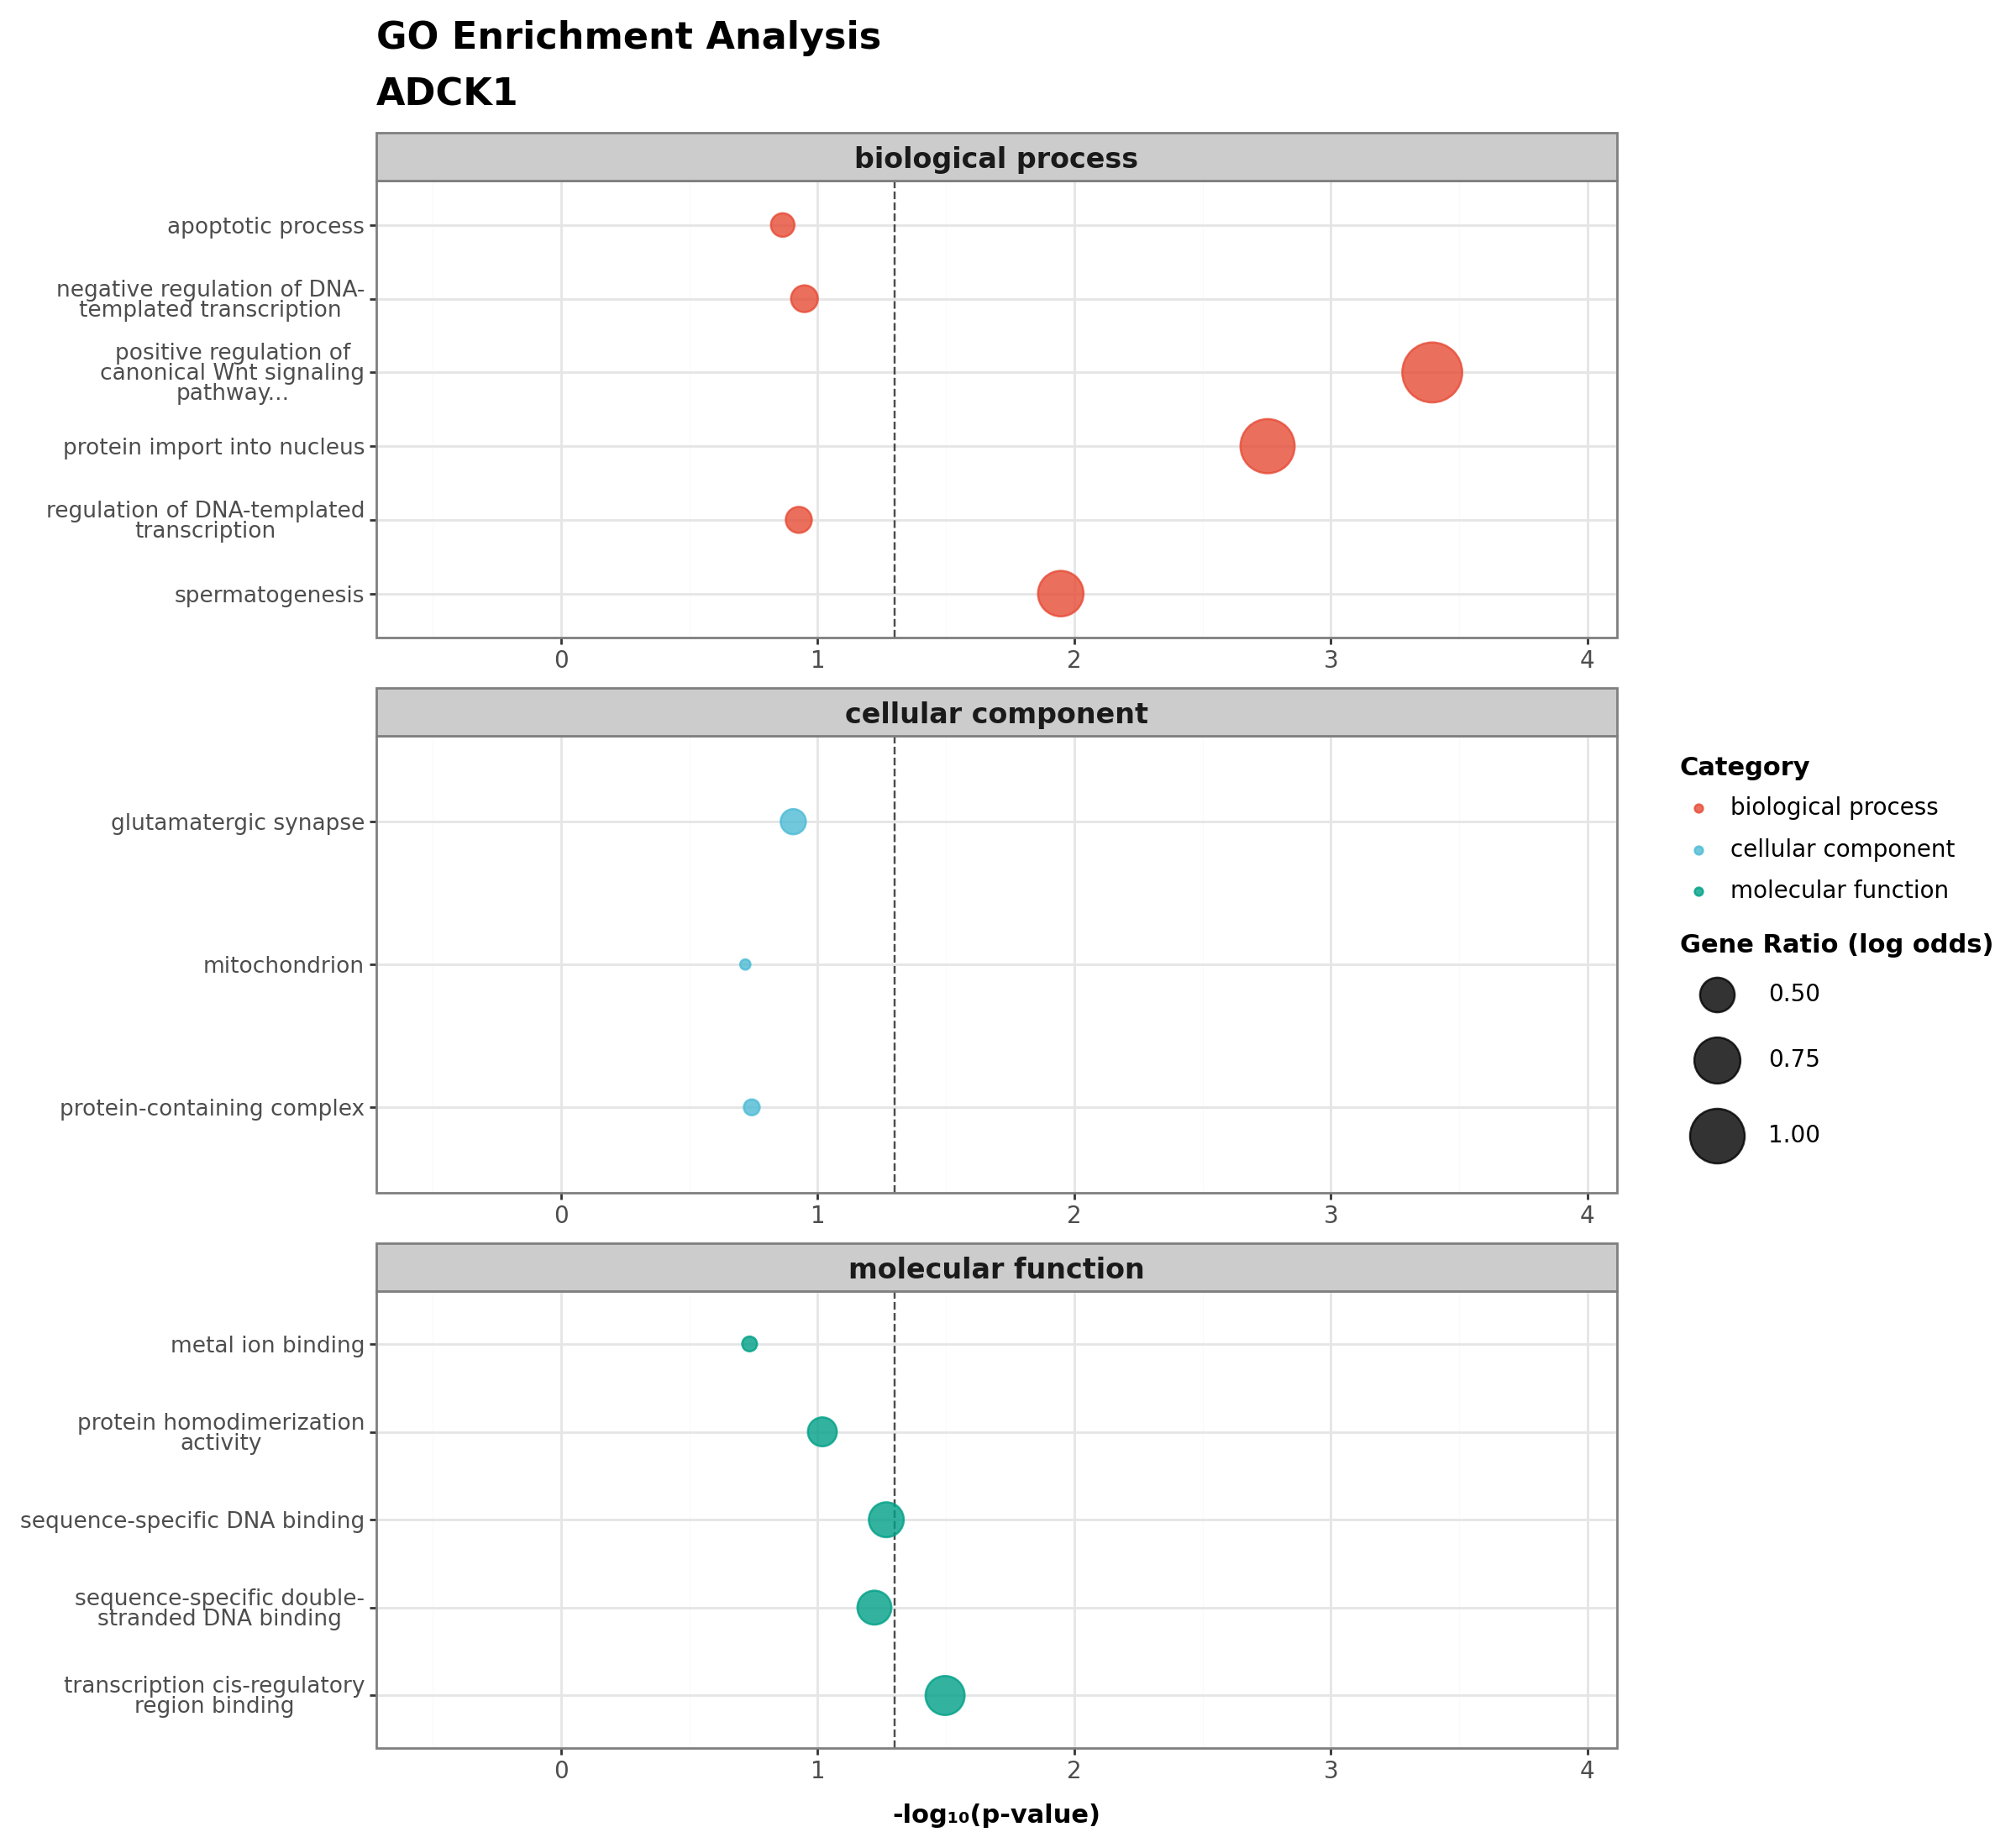

In [335]:
fig.show()

In [306]:
go_result_all = pd.concat([tmp_dat_ADCK1_HUMAN,tmp_dat_KKCC1_HUMAN,tmp_dat_PHKG1_HUMAN])

In [259]:
go_result_all.to_csv('./dark_kinase_out/260112_dark_kinase_go_results.csv')

In [307]:
go_result_all

,GO_ID,GO_name,GO_type,hit_with_GO,total_hits,bg_with_GO,total_bg,odds_ratio,p_value,q_value,kinase
119,GO:0090263,positive regulation of canonical Wnt signaling...,Gene Ontology (biological process),4,22,18,1249,15.197531,0.000402,0.092894,ADCK1
72,GO:0006606,protein import into nucleus,Gene Ontology (biological process),4,22,28,1249,9.690476,0.001764,0.092894,ADCK1
130,GO:0007283,spermatogenesis,Gene Ontology (biological process),4,22,49,1249,5.442177,0.011283,0.190104,ADCK1
164,GO:0045892,negative regulation of DNA-templated transcrip...,Gene Ontology (biological process),4,22,105,1249,2.421164,0.112528,0.224585,ADCK1
121,GO:0006355,regulation of DNA-templated transcription,Gene Ontology (biological process),4,22,107,1249,2.371755,0.118387,0.229910,ADCK1
89,GO:0006915,apoptotic process,Gene Ontology (biological process),4,22,113,1249,2.234022,0.136787,0.247027,ADCK1
79,GO:0098978,glutamatergic synapse,Gene Ontology (cellular component),4,22,109,1249,2.324159,0.124385,0.236687,ADCK1
14,GO:0032991,protein-containing complex,Gene Ontology (cellular component),4,22,126,1249,1.980600,0.180533,0.273041,ADCK1
57,GO:0005739,mitochondrion,Gene Ontology (cellular component),4,22,129,1249,1.929371,0.191301,0.280463,ADCK1
153,GO:0000976,transcription cis-regulatory region binding,Gene Ontology (molecular function),4,22,68,1249,3.859477,0.031855,0.190104,ADCK1


In [308]:
curr_hits = sub_ann_final.loc[sub_ann_final['kinase']=='ADCK1_HUMAN',['Entry','Protein names','kinase','Gene Ontology (GO)']]
curr_hits.shape
# curr_hits.loc[curr_hits['Gene Ontology (GO)'].apply(lambda s: 'spermatogenesis' in s),:]['Protein names'].tolist()

(21, 4)

In [260]:
go_result_all

,GO_ID,GO_name,GO_type,hit_with_GO,total_hits,bg_with_GO,total_bg,odds_ratio,p_value,q_value,kinase
119,GO:0090263,positive regulation of canonical Wnt signaling...,Gene Ontology (biological process),4,22,18,1249,15.197531,0.000402,0.092894,ADCK1
72,GO:0006606,protein import into nucleus,Gene Ontology (biological process),4,22,28,1249,9.690476,0.001764,0.092894,ADCK1
130,GO:0007283,spermatogenesis,Gene Ontology (biological process),4,22,49,1249,5.442177,0.011283,0.190104,ADCK1
164,GO:0045892,negative regulation of DNA-templated transcrip...,Gene Ontology (biological process),4,22,105,1249,2.421164,0.112528,0.224585,ADCK1
121,GO:0006355,regulation of DNA-templated transcription,Gene Ontology (biological process),4,22,107,1249,2.371755,0.118387,0.229910,ADCK1
89,GO:0006915,apoptotic process,Gene Ontology (biological process),4,22,113,1249,2.234022,0.136787,0.247027,ADCK1
79,GO:0098978,glutamatergic synapse,Gene Ontology (cellular component),4,22,109,1249,2.324159,0.124385,0.236687,ADCK1
14,GO:0032991,protein-containing complex,Gene Ontology (cellular component),4,22,126,1249,1.980600,0.180533,0.273041,ADCK1
57,GO:0005739,mitochondrion,Gene Ontology (cellular component),4,22,129,1249,1.929371,0.191301,0.280463,ADCK1
153,GO:0000976,transcription cis-regulatory region binding,Gene Ontology (molecular function),4,22,68,1249,3.859477,0.031855,0.190104,ADCK1
